# SFT 数据观察

看 SmolDataEnvs-sft 这 4,677 条轨迹：转成 Qwen3 chat 模板（含 tools、thinking 关闭）之后有多长、几轮、覆盖率如何，以及终点答案能不能过 strict 检查。

> 在项目根目录 `smoldataenvs-win/` 下打开本 notebook（VS Code 选 anaconda 的 python 内核）。

In [1]:
from pathlib import Path
import json, sys, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name != "smoldataenvs-win":          # 不在项目根目录就手动改这里
    ROOT = Path(r"d:\python\python_code\torch_learnling\LLM_Research\smoldataenvs-win")
sys.path.insert(0, str(ROOT))

PARQUET = ROOT / "data/SmolDataEnvs-sft/data/train-00000-of-00001.parquet"
MODEL   = ROOT / "models/Qwen3-0.6B"
df = pd.read_parquet(PARQUET)
print(len(df), "rows")
df[["task_id", "difficulty_tier", "n_turns", "source_agent"]].head()

4677 rows


,task_id,difficulty_tier,n_turns,source_agent
0,0032_386_32386426_qa_2,medium,7,bash
1,0079_726_79726462_qa_1,medium,3,bash
2,0058_272_58272349_qa_4,easy,3,bash
3,0108_986_108986276_qa_3,medium,3,bash
4,0135_720_135720396_qa_1,medium,6,bash


In [3]:
from transformers import AutoTokenizer
from train_sft_local import _plain

tok = AutoTokenizer.from_pretrained(MODEL)

def render(row):
    """一条轨迹 -> Qwen3 模板文本（和训练/评测完全同一条路径）"""
    msgs = [json.loads(m) for m in row.messages]
    return tok.apply_chat_template(
        msgs, tools=_plain(list(row.tools)), tokenize=False,
        add_generation_prompt=False, chat_template_kwargs={"enable_thinking": False})

print(render(df.iloc[0]))

<|im_start|>system
You are an autonomous data-analysis agent operating in a sandboxed Linux container. Your only tool is `bash`. The dataset files are in /home/user/input/. Python 3 + pandas + numpy + scikit-learn + scipy are pre-installed.

Work the problem step-by-step: first inspect the data (ls, head, shape, dtypes), then plan, then compute, then submit.

To submit your final answer you MUST call the `bash` tool to write it to /workdir/answer.txt, e.g. `echo -n "<value>" > /workdir/answer.txt`. Keep the answer short and concise. Do NOT end your turn without submitting.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "bash", "description": "Run a shell command in the sandbox and return its combined stdout+stderr. The shell is non-stateful between calls (each call is a fresh `bash -c`). Use it to explore files (ls, head, cat), run P

In [4]:
# 全量 token 长度（首次约 1~2 分钟，之后走缓存）
CACHE = ROOT / "runs/_sft_token_lengths.json"
if CACHE.exists():
    lens = np.array(json.loads(CACHE.read_text()))
else:
    lens = np.array([len(tok(render(r), add_special_tokens=False)["input_ids"])
                     for r in df.itertuples()])
    CACHE.write_text(json.dumps(lens.tolist()))

print("n        =", len(lens))
print("mean     =", round(lens.mean(), 1))
print("max      =", lens.max())
for p in (50, 75, 90, 95, 97, 99):
    print(f"p{p:<2}      =", int(np.percentile(lens, p)))

n        = 4677
mean     = 1911.2
max      = 23340
p50      = 1457
p75      = 1995
p90      = 3015
p95      = 4538
p97      = 5771
p99      = 8563


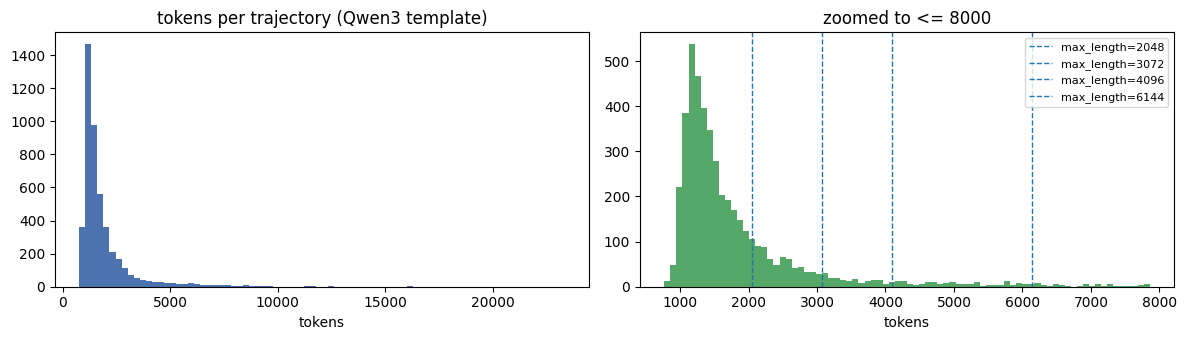

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(lens, bins=80, color="#4c72b0")
ax[0].set_title("tokens per trajectory (Qwen3 template)"); ax[0].set_xlabel("tokens")
ax[1].hist(lens[lens <= 8000], bins=80, color="#55a868")
ax[1].set_title("zoomed to <= 8000"); ax[1].set_xlabel("tokens")
for cap in (2048, 3072, 4096, 6144):
    ax[1].axvline(cap, ls="--", lw=1, label=f"max_length={cap}")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
# 不同 max_length 的覆盖率 / 被截断条数
n = len(lens)
for cap in (1536, 2048, 2560, 3072, 4096, 4608, 6144, 8192):
    kept = int((lens <= cap).sum())
    print(f"cap {cap:5d}: 覆盖 {kept/n*100:5.1f}%  ({kept}/{n})   截断 {n-kept:4d} 条")

cap  1536: 覆盖  55.2%  (2584/4677)   截断 2093 条
cap  2048: 覆盖  76.3%  (3570/4677)   截断 1107 条
cap  2560: 覆盖  85.4%  (3996/4677)   截断  681 条
cap  3072: 覆盖  90.4%  (4227/4677)   截断  450 条
cap  4096: 覆盖  94.1%  (4401/4677)   截断  276 条
cap  4608: 覆盖  95.1%  (4447/4677)   截断  230 条
cap  6144: 覆盖  97.6%  (4563/4677)   截断  114 条
cap  8192: 覆盖  98.8%  (4622/4677)   截断   55 条


tool turns : p50=3 p90=5 p95=6 p99=10 max=20
model calls: p50=4 p90=6 p95=7 p99=11 max=21


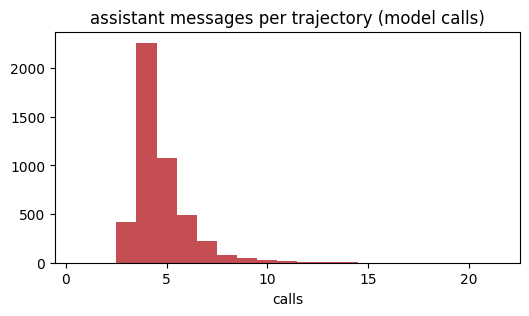

model calls <= 6 : 90.7%
model calls <= 10: 98.8%


In [7]:
# 轮数：工具轮数(n_turns) vs 模型调用次数（assistant 消息数）
tool_turns   = df.n_turns.values
model_calls  = np.array([sum(1 for m in [json.loads(x) for x in r.messages] if m["role"] == "assistant")
                         for r in df.itertuples()])

def pct(a, name):
    print(f"{name}: p50={np.percentile(a,50):.0f} p90={np.percentile(a,90):.0f} "
          f"p95={np.percentile(a,95):.0f} p99={np.percentile(a,99):.0f} max={a.max()}")

pct(tool_turns,  "tool turns ")
pct(model_calls, "model calls")

plt.figure(figsize=(6, 3))
plt.hist(model_calls, bins=range(1, model_calls.max() + 2), color="#c44e52", align="left")
plt.title("assistant messages per trajectory (model calls)"); plt.xlabel("calls"); plt.show()
print("model calls <= 6 :", f"{(model_calls<=6).mean()*100:.1f}%")
print("model calls <= 10:", f"{(model_calls<=10).mean()*100:.1f}%")

In [8]:
# 终点质量：最后写 answer.txt 的值能不能过 strict(v2) / lenient(v1)
import re
import smolenv_local as env
from eval_harness import load_tasks

train = {r["task_id"]: r for r in load_tasks("train")}

def final_answer(msgs):
    val, writes = None, 0
    for m in msgs:
        for tc in (m.get("tool_calls") or []):
            cmd = tc["function"]["arguments"].get("command", "")
            if "answer.txt" in cmd:
                writes += 1
                hit = re.findall(r'''echo\s+-n\s+["'](.*?)["']\s*>\s*/workdir/answer.txt''', cmd, re.S) \
                      or re.findall(r'''(?:printf|echo)\s+(.*?)\s*>\s*/workdir/answer.txt''', cmd, re.S)
                if hit: val = hit[-1]
    return val, writes

reasons, v1ok, v2ok, tot, no_write = collections.Counter(), 0, 0, 0, 0
for r in df.itertuples():
    v, w = final_answer([json.loads(m) for m in r.messages])
    if v is None:
        no_write += 1
        continue
    res = env.score(train[r.task_id], v)
    tot += 1
    v1ok += bool(res.get("reward_v1")); v2ok += bool(res.get("reward_v2"))
    reasons[res.get("reason_v2")] += 1

print(f"可解析 {tot} 条，无有效写入 {no_write} 条")
print(f"v1 宽松通过 {v1ok/tot*100:.1f}%   v2 严格通过 {v2ok/tot*100:.1f}%")
print(reasons.most_common(10))

可解析 4445 条，无有效写入 232 条
v1 宽松通过 81.7%   v2 严格通过 50.5%
[('numeric', 1316), ('not_a_bare_number', 1052), ('exact', 713), ('miss', 623), ('numeric_miss', 243), ('list_ordered', 117), ('list_order_or_value', 81), ('list_length', 80), ('bool', 77), ('list_miss', 59)]


In [9]:
# 看某一条的逐轮内容（改成你想看的 task_id）
TASK = df.task_id.iloc[0]
row = df[df.task_id == TASK].iloc[0]
for m in [json.loads(x) for x in row.messages]:
    c = m.get("content") or ""
    print(f"[{m['role']}] {c[:120]!r}", "TOOL_CALL" if m.get("tool_calls") else "")

[system] 'You are an autonomous data-analysis agent operating in a sandboxed Linux container. Your only tool is `bash`. The datase' 
[user] 'You are a data-analysis agent working in a sandbox. Use your code-execution tool to inspect the files and compute the an' 
[assistant] "I'll analyze the bank.csv file step by step to answer the question about age ranges with the highest likelihood of term " TOOL_CALL
[tool] 'bank.csv\nage,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutc' 
[assistant] '' TOOL_CALL
[tool] '/bin/bash: line 1: import: command not found\n/bin/bash: line 2: import: command not found\n/bin/bash: -c: line 3: syntax ' 
[assistant] '' TOOL_CALL
[tool] 'Shape: (11162, 17)\nDtypes: age          int64\njob            str\nmarital        str\neducation      str\ndefault        st' 
[assistant] '' TOOL_CALL
[tool] 'Peaks (age, ratio):\n  Age: 65.2, ratio: 5.986\n  Age: 70.0, ratio: 5.842\n  Age: 84.1, ratio: 5.366\n\nAge